# Hit Song Prediction — Model Training Preprocessing

This notebook covers preprocessing, baseline model training, hyperparameter tuning, and final evaluation for the Hit Song Prediction project.

## Data Loading and Preprocessing

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 2. Load the Dataset

In [2]:
final_df = pd.read_csv("../data/final_dataset.csv")
display(final_df.head())

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,hit
0,Perfidia Cha Cha,['Cal Tjader'],0.858,0.449,-16.531,0.0658,0.77400,0.062500,0.1130,0.890,127.066,0
1,Gir Kanıma,['Harun Kolçak'],0.759,0.714,-9.449,0.0564,0.00163,0.000012,0.0173,0.492,119.775,0
2,It's Over Now,['112'],0.660,0.710,-4.541,0.0409,0.01060,0.000007,0.0736,0.233,97.988,1
3,The Pusher,['Blind Melon'],0.438,0.576,-8.727,0.0320,0.03020,0.000011,0.0988,0.742,165.277,0
4,Toys In The Attic,['Aerosmith'],0.219,0.928,-9.997,0.0697,0.00100,0.000002,0.3410,0.446,197.462,0


## 3. Define Features and Target

In [3]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

X = final_df[audio_features]
y = final_df["hit"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 9)
y shape: (10000,)


## 4. Train-Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 9)
X_test shape: (2000, 9)
y_train shape: (8000,)
y_test shape: (2000,)


## 5. Train-Test Class Distributions

In [5]:
train_distribution = pd.DataFrame({
    "count": y_train.value_counts().sort_index(),
    "percentage": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
})
test_distribution = pd.DataFrame({
    "count": y_test.value_counts().sort_index(),
    "percentage": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
})

train_distribution.index.name = "hit"
test_distribution.index.name = "hit"

print("Training target distribution:")
display(train_distribution)

print("Testing target distribution:")
display(test_distribution)

Training target distribution:


,count,percentage
hit,,
0,4800,60.0
1,3200,40.0


Testing target distribution:


,count,percentage
hit,,
0,1200,60.0
1,800,40.0


## 6. Standardize the Features

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 rows of X_train_scaled:")
display(pd.DataFrame(X_train_scaled, columns=audio_features).head())

First 5 rows of X_train_scaled:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,2.020043,-0.084098,0.630174,0.018609,0.847120,3.316982,-0.251117,-1.738506,0.062656
1,-0.242930,0.323112,-0.547809,-0.398663,-1.147916,-0.359454,-0.650879,1.113310,0.504710
2,-1.747434,1.498566,1.296369,0.494105,0.466033,-0.359595,-0.614277,-0.650577,-1.735174
3,0.944509,0.352499,0.126869,-0.300410,0.916135,-0.327266,0.715406,1.617277,-0.015393
4,1.081282,-0.210040,0.570999,-0.414432,0.589061,-0.359595,0.332228,0.169370,-0.453356


## Model Training

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


## Logistic Regression

In [8]:
logistic_regression = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression.fit(X_train_scaled, y_train)
logistic_predictions = logistic_regression.predict(X_test_scaled)
print("Logistic Regression training completed.")

Logistic Regression training completed.


## Decision Tree

In [9]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)
decision_tree_predictions = decision_tree.predict(X_test)
print("Decision Tree training completed.")

Decision Tree training completed.


## SVM

In [10]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)
print("SVM training completed.")

SVM training completed.


## KNN

In [11]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)
print("KNN training completed.")

KNN training completed.


## Artificial Neural Network (ANN)

An artificial neural network is a layered function that learns a relationship between input features and a target. In this project, the input layer contains the nine Spotify audio features. Each hidden layer contains neurons, and each neuron combines incoming values using learned weights and a bias before applying an activation function. The output represents the binary HIT/NON-HIT prediction.

During **forward propagation**, feature values move from the input layer through the hidden layers to the output. The model calculates a loss by comparing its prediction with the true label. During **backpropagation**, gradients of that loss are propagated backward, and an optimizer updates the weights and biases. ReLU is used for the hidden layers because it introduces non-linearity while remaining efficient. `MLPClassifier` provides the binary classification output and probability interface internally; a manually specified sigmoid output layer is not required.

The Adam optimizer adapts the learning rate for each parameter using gradient information. StandardScaler is important for an ANN because features such as tempo and loudness have different numeric scales; scaling prevents larger-valued features from dominating optimization. The ANN uses the same stratified 80:20 split and the training-fitted scaler as the other scaled models, so the comparison remains fair and avoids test-data leakage. `MLPClassifier` performs forward propagation, loss calculation, backpropagation, and weight updates internally during `.fit()`.


In [12]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)
ann_model.fit(X_train_scaled, y_train)
ann_predictions = ann_model.predict(X_test_scaled)
ann_probabilities = ann_model.predict_proba(X_test_scaled)[:, 1]

print("ANN training completed.")
print("ANN iterations:", ann_model.n_iter_)


ANN training completed.
ANN iterations: 47


## Initial Model Comparison

In [13]:
def calculate_metrics(model_name, y_true, predictions, probabilities=None):
    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1_score": f1_score(y_true, predictions, zero_division=0),
    }
    if probabilities is not None:
        metrics["roc_auc"] = roc_auc_score(y_true, probabilities)
    return metrics

results_df = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_test, logistic_predictions),
    calculate_metrics("Decision Tree", y_test, decision_tree_predictions),
    calculate_metrics("SVM", y_test, svm_predictions),
    calculate_metrics("KNN", y_test, knn_predictions),
    calculate_metrics("ANN", y_test, ann_predictions, ann_probabilities),
]).sort_values("f1_score", ascending=False).reset_index(drop=True)

display(results_df)


,model,accuracy,precision,recall,f1_score,roc_auc
0,ANN,0.6615,0.570125,0.62500,0.596303,0.732302
1,SVM,0.6660,0.593484,0.52375,0.556441,NaN
2,Logistic Regression,0.6445,0.557419,0.54000,0.548571,NaN
3,KNN,0.6335,0.540705,0.55625,0.548367,NaN
4,Decision Tree,0.6015,0.501845,0.51000,0.505890,NaN


## Confusion Matrices and Classification Reports

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

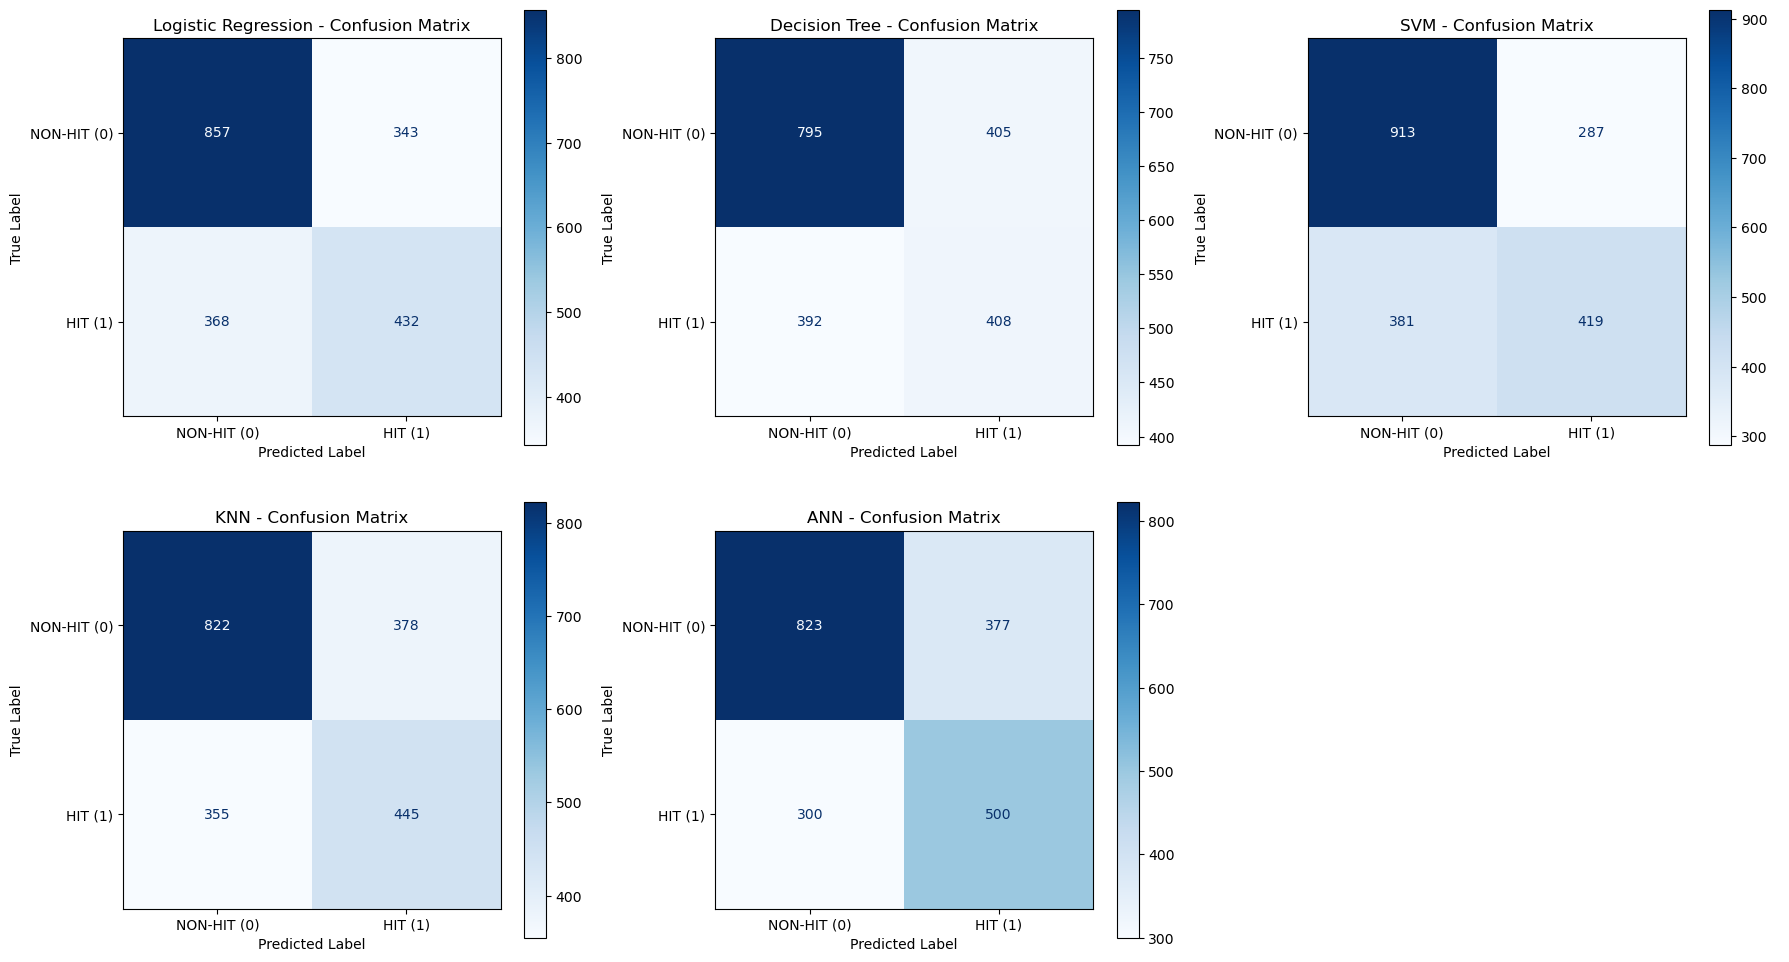

In [ ]:

model_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "SVM": svm_predictions,
    "KNN": knn_predictions,
    "ANN": ann_predictions,  
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (model_name, predictions) in enumerate(model_predictions.items()):
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["NON-HIT (0)", "HIT (1)"],
    )

    display_plot.plot(
        ax=axes[i],
        cmap="Blues",
        values_format="d",
    )

    axes[i].set_title(f"{model_name} - Confusion Matrix")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

# Hide the unused sixth subplot
for j in range(len(model_predictions), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


In [16]:
for model_name, predictions in {
    **model_predictions,
    "ANN": ann_predictions,
}.items():
    print(f"{model_name} - Classification Report")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["NON-HIT (0)", "HIT (1)"],
        zero_division=0,
    ))

Logistic Regression - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.70      0.71      0.71      1200
     HIT (1)       0.56      0.54      0.55       800

    accuracy                           0.64      2000
   macro avg       0.63      0.63      0.63      2000
weighted avg       0.64      0.64      0.64      2000

Decision Tree - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.67      0.66      0.67      1200
     HIT (1)       0.50      0.51      0.51       800

    accuracy                           0.60      2000
   macro avg       0.59      0.59      0.59      2000
weighted avg       0.60      0.60      0.60      2000

SVM - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.71      0.76      0.73      1200
     HIT (1)       0.59      0.52      0.56       800

    accuracy                           0.67      2000
   macro avg      

In [26]:

print("Available models:", list(model_predictions.keys()))

print("\nANN - Classification Report")
print(classification_report(
    y_test,
    model_predictions["ANN"],
    labels=[0, 1],
    target_names=["NON-HIT (0)", "HIT (1)"],
    zero_division=0,
))


Available models: ['Logistic Regression', 'Decision Tree', 'SVM', 'KNN', 'ANN']

ANN - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.73      0.69      0.71      1200
     HIT (1)       0.57      0.62      0.60       800

    accuracy                           0.66      2000
   macro avg       0.65      0.66      0.65      2000
weighted avg       0.67      0.66      0.66      2000



## Confusion Matrix Analysis

A confusion matrix shows how many songs were correctly and incorrectly classified for each class. The rows represent the true labels, while the columns represent the predicted labels. The diagonal entries are correct predictions, and the off-diagonal entries are classification errors.

Based on the existing F1-score results, SVM currently performs best, with the highest F1-score among the four models.

## Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

tuning_configs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(max_iter=1000, random_state=42),
        "parameters": {"C": [0.01, 0.1, 1, 10, 100]},
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "parameters": {
            "max_depth": [3, 5, 7, 10, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
        },
        "X_train": X_train,
        "X_test": X_test,
    },
    "SVM": {
        "estimator": SVC(random_state=42),
        "parameters": {
            "C": [0.1, 1, 10],
            "kernel": ["linear", "rbf"],
        },
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
    "KNN": {
        "estimator": KNeighborsClassifier(),
        "parameters": {
            "n_neighbors": [3, 5, 7, 9, 11],
            "weights": ["uniform", "distance"],
        },
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
    "ANN": {
        "estimator": MLPClassifier(
            activation="relu",
            solver="adam",
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=20,
            random_state=42,
        ),
        "parameters": {
            "hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
            "alpha": [0.0001, 0.001],
        },
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
    },
}

tuned_models = {}
tuned_predictions = {}
tuned_results = []

for model_name, config in tuning_configs.items():
    grid_search = GridSearchCV(
        estimator=config["estimator"],
        param_grid=config["parameters"],
        cv=5,
        scoring="f1",
        n_jobs=-1, # Use all available cores for parallel processing
    )
    grid_search.fit(config["X_train"], y_train)
    predictions = grid_search.predict(config["X_test"])

    tuned_models[model_name] = grid_search.best_estimator_
    tuned_predictions[model_name] = predictions
    if hasattr(grid_search.best_estimator_, "predict_proba"):
        tuned_scores_for_auc = grid_search.best_estimator_.predict_proba(config["X_test"])[:, 1]
    elif hasattr(grid_search.best_estimator_, "decision_function"):
        tuned_scores_for_auc = grid_search.best_estimator_.decision_function(config["X_test"])
    else:
        tuned_scores_for_auc = None

    tuned_results.append({
        "Model": model_name,
        "Best Parameters": grid_search.best_params_,
        "CV F1-score": grid_search.best_score_,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Precision": precision_score(y_test, predictions, zero_division=0),
        "Test Recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1-score": f1_score(y_test, predictions, zero_division=0),
        "Test ROC-AUC": (
            roc_auc_score(y_test, tuned_scores_for_auc)
            if tuned_scores_for_auc is not None
            else np.nan
        ),
    })

    print(f"{model_name} best parameters: {grid_search.best_params_}")
    print(f"{model_name} best cross-validation F1-score: {grid_search.best_score_:.4f}")

# Selection is based on training-only cross-validation F1, not held-out test F1.
tuned_results_df = pd.DataFrame(tuned_results).sort_values(
    "CV F1-score", ascending=False
).reset_index(drop=True)

display(tuned_results_df)


Logistic Regression best parameters: {'C': 100}
Logistic Regression best cross-validation F1-score: 0.5414
Decision Tree best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Decision Tree best cross-validation F1-score: 0.6226
SVM best parameters: {'C': 0.1, 'kernel': 'linear'}
SVM best cross-validation F1-score: 0.5810
KNN best parameters: {'n_neighbors': 3, 'weights': 'uniform'}
KNN best cross-validation F1-score: 0.5397
ANN best parameters: {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)}
ANN best cross-validation F1-score: 0.5829


,Model,Best Parameters,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score,Test ROC-AUC
0,Decision Tree,"{'max_depth': 3, 'min_samples_leaf': 1, 'min_s...",0.622624,0.6195,0.515688,0.80125,0.627509,0.671120
1,ANN,"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)}",0.582876,0.6615,0.570125,0.62500,0.596303,0.732302
2,SVM,"{'C': 0.1, 'kernel': 'linear'}",0.580974,0.6390,0.542299,0.62500,0.580720,0.702137
3,Logistic Regression,{'C': 100},0.541385,0.6445,0.557419,0.54000,0.548571,0.702909
4,KNN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.539721,0.6190,0.523869,0.52125,0.522556,0.658367


## Baseline vs Tuned Comparison

In [18]:
baseline_f1 = results_df[["model", "f1_score"]].rename(columns={
    "model": "Model",
    "f1_score": "Baseline F1-score",
})
tuned_f1 = tuned_results_df[["Model", "Test F1-score"]].rename(columns={
    "Test F1-score": "Tuned F1-score",
})

baseline_tuned_comparison_df = baseline_f1.merge(tuned_f1, on="Model")
baseline_tuned_comparison_df["F1-score Change"] = (
    baseline_tuned_comparison_df["Tuned F1-score"]
    - baseline_tuned_comparison_df["Baseline F1-score"]
)

display(baseline_tuned_comparison_df)
best_tuned_model_name = tuned_results_df.iloc[0]["Model"]
best_tuned_model = tuned_results_df.iloc[0]
print(
    f"Highest cross-validation F1-score: {best_tuned_model_name} "
    f"({best_tuned_model['CV F1-score']:.4f})"
)


,Model,Baseline F1-score,Tuned F1-score,F1-score Change
0,ANN,0.596303,0.596303,0.000000
1,SVM,0.556441,0.580720,0.024279
2,Logistic Regression,0.548571,0.548571,0.000000
3,KNN,0.548367,0.522556,-0.025811
4,Decision Tree,0.505890,0.627509,0.121619


Highest cross-validation F1-score: Decision Tree (0.6226)


## Hyperparameter Tuning Analysis

Hyperparameter tuning was performed to systematically evaluate reasonable parameter combinations using five-fold cross-validation and F1-score, rather than relying only on the baseline defaults. This helps identify settings that balance precision and recall for HIT songs.

The comparison table shows that Decision Tree improved the most compared with its baseline, increasing its test F1-score from 0.5059 to 0.6275. Decision Tree also has the highest tuned test F1-score at 0.6275. Overall performance improved because the best tuned test F1-score is higher than the best baseline F1-score of 0.5564.

## Final Model Evaluation

In [19]:
selected_model_name = tuned_results_df.iloc[0]["Model"]
selected_model = tuned_models[selected_model_name]
selected_X_test = tuning_configs[selected_model_name]["X_test"]
final_predictions = selected_model.predict(selected_X_test)

final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(y_test, final_predictions, zero_division=0)
final_recall = recall_score(y_test, final_predictions, zero_division=0)
final_f1_score = f1_score(y_test, final_predictions, zero_division=0)

print(f"Selected model by CV F1-score: {selected_model_name}")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall: {final_recall:.4f}")
print(f"F1-score: {final_f1_score:.4f}")


Selected model by CV F1-score: Decision Tree
Accuracy: 0.6195
Precision: 0.5157
Recall: 0.8013
F1-score: 0.6275


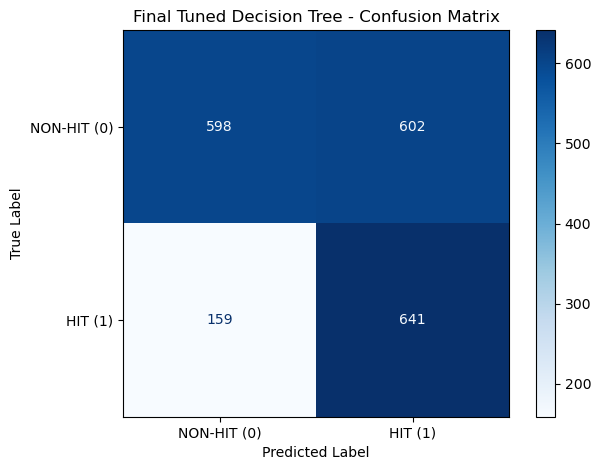

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[0, 1],
    display_labels=["NON-HIT (0)", "HIT (1)"],
    cmap="Blues",
    values_format="d",
)
plt.title(f"Final Tuned {selected_model_name} - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [21]:
print("Final Tuned Decision Tree - Classification Report")
print(classification_report(
    y_test,
    final_predictions,
    labels=[0, 1],
    target_names=["NON-HIT (0)", "HIT (1)"],
    zero_division=0,
))

Final Tuned Decision Tree - Classification Report
              precision    recall  f1-score   support

 NON-HIT (0)       0.79      0.50      0.61      1200
     HIT (1)       0.52      0.80      0.63       800

    accuracy                           0.62      2000
   macro avg       0.65      0.65      0.62      2000
weighted avg       0.68      0.62      0.62      2000



## Final Model Analysis

The final model is selected using the highest five-fold cross-validation F1-score among the tuned models, rather than using the held-out test set for model selection. The selected model and its final test metrics are printed in the evaluation cell above. Recall measures the proportion of actual HIT songs correctly identified, while precision measures how many predicted HIT songs are actually HIT. The ANN is evaluated under the same split and feature definitions but is not assumed to outperform the existing models.


## Final Results Visualization

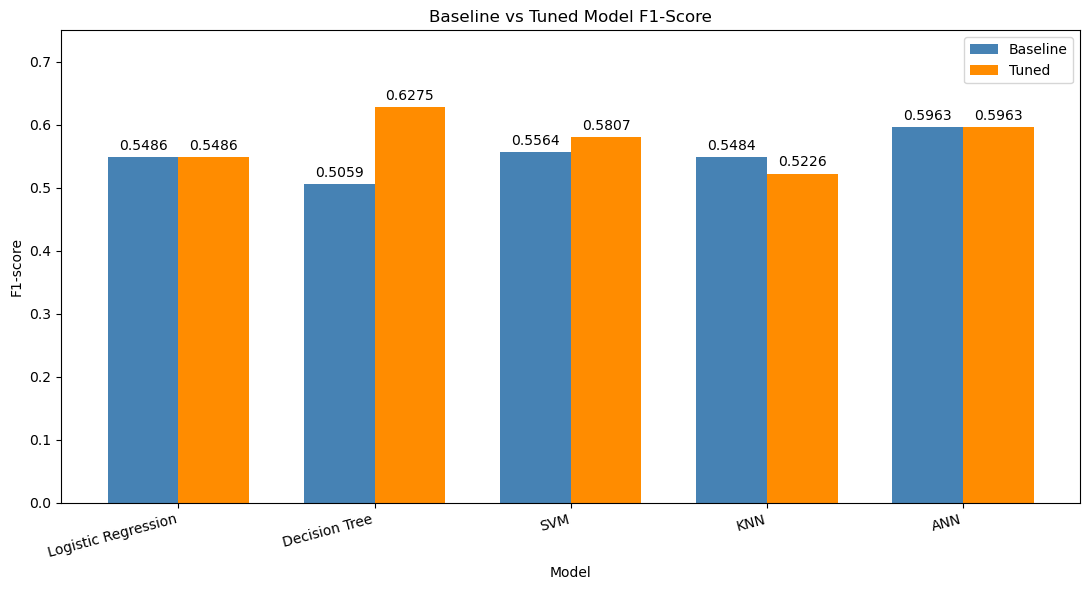

In [22]:
model_order = ["Logistic Regression", "Decision Tree", "SVM", "KNN", "ANN"]
baseline_scores = [
    results_df.loc[results_df["model"] == model, "f1_score"].iloc[0]
    for model in model_order
]
tuned_scores = [
    tuned_results_df.loc[tuned_results_df["Model"] == model, "Test F1-score"].iloc[0]
    for model in model_order
]

x_positions = np.arange(len(model_order))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))
baseline_bars = ax.bar(
    x_positions - bar_width / 2,
    baseline_scores,
    bar_width,
    label="Baseline",
    color="steelblue",
)
tuned_bars = ax.bar(
    x_positions + bar_width / 2,
    tuned_scores,
    bar_width,
    label="Tuned",
    color="darkorange",
)

ax.set_title("Baseline vs Tuned Model F1-Score")
ax.set_xlabel("Model")
ax.set_ylabel("F1-score")
ax.set_xticks(x_positions)
ax.set_xticklabels(model_order, rotation=15, ha="right")
ax.set_ylim(0, 0.75)
ax.legend()

for bars in [baseline_bars, tuned_bars]:
    ax.bar_label(bars, fmt="%.4f", padding=3)

fig.tight_layout()
plt.show()

In [ ]:
#performance is calculated for the final tuned model (Decision Tree) and displayed in a DataFrame.
final_model_summary_df = pd.DataFrame([{
    "Model": "Tuned Decision Tree",
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-score": final_f1_score,
}])

display(final_model_summary_df)

,Model,Accuracy,Precision,Recall,F1-score
0,Tuned Decision Tree,0.6195,0.515688,0.80125,0.627509


## Final Conclusion

Five classification models are evaluated: Logistic Regression, Decision Tree, SVM, KNN, and an ANN implemented with `MLPClassifier`. Hyperparameter tuning uses GridSearchCV with five-fold cross-validation and F1-score as the scoring metric. The final model is selected using the highest cross-validation F1-score, and its held-out test metrics are reported only after selection. The ANN results are included in the baseline, tuned, and comparison outputs; no improvement is assumed before execution.
